## 01. Import và đọc dữ liệu

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, balanced_accuracy_score, f1_score, recall_score
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

DATA_FILE = Path('02_merge_data/data_raw.csv')
N_ROWS = None
RANDOM_STATE = 42


In [7]:
# Đọc file đã merge như notebook gốc của nhóm
df_raw = pd.read_csv(DATA_FILE, nrows=N_ROWS, low_memory=False)

print('Kích thước dữ liệu gốc:', df_raw.shape)
print('Bộ nhớ DataFrame (MB):', round(df_raw.memory_usage(deep=True).sum() / 1024**2, 1))
display(df_raw.head())


Kích thước dữ liệu gốc: (1837498, 84)
Bộ nhớ DataFrame (MB): 1738.5


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.0,403.0,0.0,158.333333,31450.099291,177.341758,67.411331,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.0,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.5,403.0,0.0,239.666667,30619.460993,174.984174,102.039585,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.0,8.0,8.0,8.000000,0.000000,0.000000,584.368152,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.0,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,584.368152,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.0,28.0,28.0,28.000000,0.000000,0.000000,6152.248167,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.0,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6152.248167,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.0,68.0,50.0,59.000000,46.153846,6.793662,25.357414,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.0,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7.341593e+06,50763066.0,28899219.0,3.983114e+07,1.546007e+07,0,

In [8]:
# Từ điển cột rút gọn; ý nghĩa và miền hợp lệ chi tiết ở Explain_LYCOS_IDS2017.md
column_groups = {
    'Định danh/kết nối': ['flow_id', 'src_addr', 'src_port', 'dst_addr', 'dst_port', 'ip_prot', 'timestamp'],
    'Đặc trưng luồng': ['flow_duration', 'down_up_ratio', 'pkt_len_mean', 'bytes_per_s', 'pkt_per_s'],
    'Gói theo chiều': ['fwd_pkt_cnt', 'fwd_pkt_len_tot', 'bwd_pkt_cnt', 'bwd_pkt_len_tot'],
    'Khoảng cách thời gian': ['iat_min', 'iat_mean', 'fwd_iat_mean', 'bwd_iat_mean'],
    'Cờ TCP': ['flag_SYN', 'flag_ack', 'flag_rst', 'flag_psh'],
    'Nhãn/nguồn': ['label', 'source_day']
}
data_dictionary = pd.DataFrame(
    [(group, col, str(df_raw[col].dtype)) for group, cols in column_groups.items() for col in cols if col in df_raw],
    columns=['Nhóm', 'Thuộc tính', 'Kiểu dữ liệu']
)
display(data_dictionary)


,Nhóm,Thuộc tính,Kiểu dữ liệu
0,Định danh/kết nối,flow_id,object
1,Định danh/kết nối,src_addr,object
2,Định danh/kết nối,src_port,int64
3,Định danh/kết nối,dst_addr,object
4,Định danh/kết nối,dst_port,int64
5,Định danh/kết nối,ip_prot,int64
6,Định danh/kết nối,timestamp,int64
7,Đặc trưng luồng,flow_duration,int64
8,Đặc trưng luồng,down_up_ratio,float64
9,Đặc trưng luồng,pkt_len_mean,float64


## 02. EDA — cấu trúc và chất lượng dữ liệu

Các bảng ở phần này chỉ khảo sát dữ liệu; chưa sửa hay xóa bản ghi.

In [9]:
df_raw.info(memory_usage='deep')

numeric_cols = df_raw.select_dtypes(include='number').columns.tolist()
category_cols = df_raw.select_dtypes(exclude='number').columns.tolist()

quality = pd.DataFrame({
    'Kiểu dữ liệu': df_raw.dtypes.astype(str),
    'Số giá trị phân biệt': df_raw.nunique(dropna=True),
    'Số giá trị thiếu': df_raw.isna().sum(),
    'Tỷ lệ thiếu (%)': (df_raw.isna().mean() * 100).round(3)
})
display(quality.sort_values('Tỷ lệ thiếu (%)', ascending=False))
display(df_raw[numeric_cols].describe().T)
display(df_raw[category_cols].describe().T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1837498 entries, 0 to 1837497
Data columns (total 84 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   flow_id                 object 
 1   src_addr                object 
 2   src_port                int64  
 3   dst_addr                object 
 4   dst_port                int64  
 5   ip_prot                 int64  
 6   timestamp               int64  
 7   flow_duration           int64  
 8   down_up_ratio           float64
 9   pkt_len_max             float64
 10  pkt_len_min             float64
 11  pkt_len_mean            float64
 12  pkt_len_var             float64
 13  pkt_len_std             float64
 14  bytes_per_s             float64
 15  pkt_per_s               float64
 16  fwd_pkt_per_s           float64
 17  bwd_pkt_per_s           float64
 18  fwd_pkt_cnt             int64  
 19  fwd_pkt_len_tot         int64  
 20  fwd_pkt_len_max         float64
 21  fwd_pkt_len_min         float64

,Kiểu dữ liệu,Số giá trị phân biệt,Số giá trị thiếu,Tỷ lệ thiếu (%)
flow_id,object,942759,0,0.0
active_std,float64,174805,0,0.0
flag_ack,int64,2152,0,0.0
flag_rst,int64,2,0,0.0
flag_fin,int64,2,0,0.0
...,...,...,...,...
fwd_non_empty_pkt_cnt,int64,309,0,0.0
fwd_pkt_hdr_len_min,int64,9,0,0.0
fwd_pkt_hdr_len_tot,int64,3435,0,0.0
fwd_pkt_len_std,float64,201057,0,0.0


,count,mean,std,min,25%,50%,75%,max
src_port,1837498.0,4.851412e+04,1.580724e+04,0.000000e+00,4.278400e+04,5.344800e+04,6.018100e+04,6.553500e+04
dst_port,1837498.0,1.016174e+03,5.216598e+03,0.000000e+00,5.300000e+01,8.000000e+01,4.430000e+02,6.552900e+04
ip_prot,1837498.0,1.131388e+01,5.542912e+00,1.000000e+00,6.000000e+00,6.000000e+00,1.700000e+01,1.320000e+02
timestamp,1837498.0,1.499277e+15,1.302638e+11,1.499083e+15,1.499175e+15,1.499263e+15,1.499435e+15,1.499458e+15
flow_duration,1837498.0,1.199375e+07,3.091508e+07,0.000000e+00,3.240000e+02,6.205000e+04,1.459716e+06,1.200000e+08
...,...,...,...,...,...,...,...,...
fwd_subflow_pkt_mean,1837498.0,6.813951e+00,7.225960e+02,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,2.197590e+05
bwd_subflow_bytes_mean,1837498.0,1.395996e+04,2.151137e+06,0.000000e+00,9.800000e+01,2.060000e+02,1.762500e+03,6.554523e+08
bwd_subflow_pkt_mean,1837498.0,8.270970e+00,9.674378e+02,0.000000e+00,1.000000e+00,2.000000e+00,3.500000e+00,2.919220e+05
fwd_tcp_init_win_bytes,1837498.0,1.069511e+04,1.568257e+04,-1.000000e+00,-1.000000e+00,3.640000e+02,2.920000e+04,6.553500e+04


,count,unique,top,freq
flow_id,1837498,942759,192.168.10.3-192.168.10.255-137-137-17,451
src_addr,1837498,268,172.16.0.1,442471
dst_addr,1837498,18095,192.168.10.3,602976
label,1837498,14,benign,1395675
source_day,1837498,5,Friday,542962


In [10]:
# Trùng toàn dòng khác với flow_id lặp: cùng kết nối có thể xuất hiện ở nhiều thời điểm
duplicate_count = int(df_raw.duplicated().sum())
flow_id_repeated = int(df_raw.duplicated(subset=['flow_id']).sum())
inf_count = int(np.isinf(df_raw[numeric_cols].to_numpy()).sum())

quality_summary = pd.DataFrame({
    'Chỉ tiêu': ['Số dòng', 'Số cột gốc', 'Giá trị thiếu', 'Giá trị vô cực', 'Trùng toàn dòng', 'flow_id lặp'],
    'Kết quả': [len(df_raw), df_raw.shape[1], int(df_raw.isna().sum().sum()),
                inf_count, duplicate_count, flow_id_repeated]
})
display(quality_summary)


,Chỉ tiêu,Kết quả
0,Số dòng,1837498
1,Số cột gốc,84
2,Giá trị thiếu,0
3,Giá trị vô cực,0
4,Trùng toàn dòng,0
5,flow_id lặp,894739


In [11]:
# Miền giá trị theo từ điển dữ liệu; -1 ở TCP window là mã không ghi nhận, không phải lỗi âm
issue_rows = []
for col in ['src_port', 'dst_port', 'ip_prot']:
    upper = 255 if col == 'ip_prot' else 65535
    bad = df_raw[col].notna() & (~df_raw[col].between(0, upper) | df_raw[col].mod(1).ne(0))
    issue_rows.append([col, 'Ngoài miền hoặc không nguyên', int(bad.sum())])

nonnegative_cols = [c for c in numeric_cols if c not in
                    ['src_port', 'dst_port', 'ip_prot', 'timestamp',
                     'fwd_tcp_init_win_bytes', 'bwd_tcp_init_win_bytes']]
for col in nonnegative_cols:
    n_bad = int(df_raw[col].lt(0).sum())
    if n_bad:
        issue_rows.append([col, 'Giá trị âm', n_bad])

for col in ['fwd_tcp_init_win_bytes', 'bwd_tcp_init_win_bytes']:
    issue_rows.append([col, 'Mã -1 (không ghi nhận)', int(df_raw[col].eq(-1).sum())])

issue_table = pd.DataFrame(issue_rows, columns=['Cột', 'Vấn đề', 'Số giá trị'])
display(issue_table[issue_table['Số giá trị'] > 0].sort_values('Số giá trị', ascending=False))


,Cột,Vấn đề,Số giá trị
5,bwd_tcp_init_win_bytes,Mã -1 (không ghi nhận),898080
4,fwd_tcp_init_win_bytes,Mã -1 (không ghi nhận),887683
3,iat_min,Giá trị âm,2270


In [12]:
# Chỉ vẽ thuộc tính thiếu thực sự, không tạo biểu đồ rỗng
missing_plot = quality[quality['Số giá trị thiếu'] > 0].sort_values('Tỷ lệ thiếu (%)')
if len(missing_plot):
    ax = missing_plot['Tỷ lệ thiếu (%)'].plot.barh(figsize=(9, 4), color='steelblue')
    ax.set(xlabel='Tỷ lệ thiếu (%)', ylabel='Thuộc tính', title='Thuộc tính có giá trị thiếu')
    plt.tight_layout()
    plt.show()
else:
    print('Dữ liệu gốc không có giá trị thiếu dạng NaN; xem thêm các giá trị ngoài miền ở bảng trên.')


Dữ liệu gốc không có giá trị thiếu dạng NaN; xem thêm các giá trị ngoài miền ở bảng trên.


## 03. EDA — phân bố biến mục tiêu

,label,count,percent
0,benign,1395675,75.955
1,portscan,160106,8.713
2,dos_hulk,158988,8.652
3,ddos,95683,5.207
4,dos_goldeneye,6765,0.368
5,dos_slowloris,5674,0.309
6,dos_slowhttptest,4866,0.265
7,ftp_patator,4003,0.218
8,ssh_patator,2959,0.161
9,webattack_bruteforce,1360,0.074


,Lớp,count,percent
0,safe,1395675,75.955
1,attack,441823,24.045


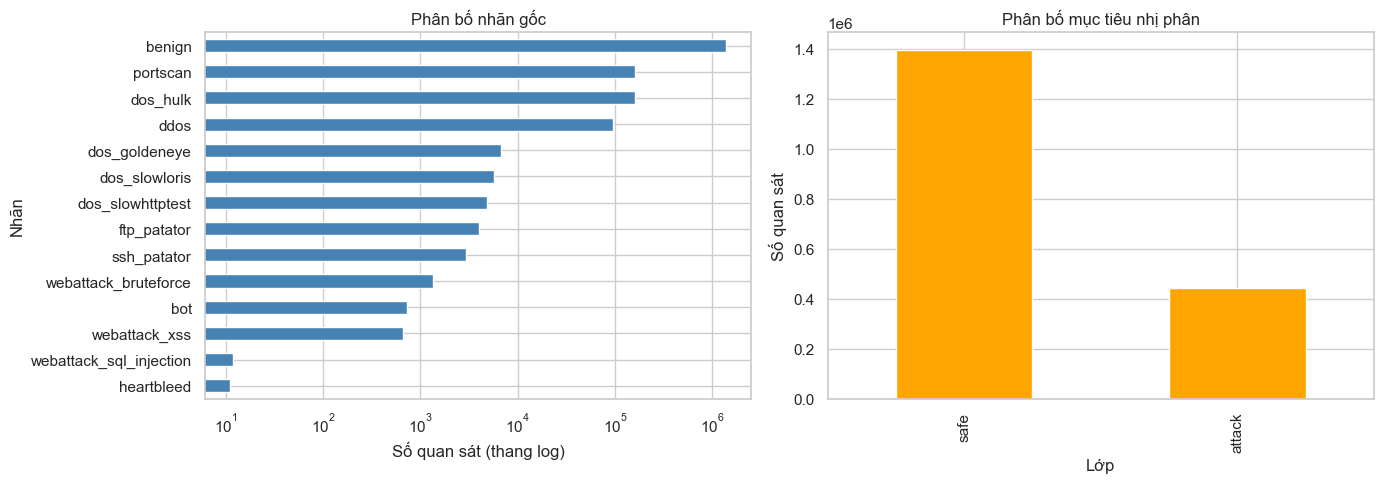

Tỷ lệ lớp lớn nhất / nhỏ nhất: 3.16
Khi đánh giá mô hình cần xem thêm recall, F1, balanced accuracy và average precision; không chỉ accuracy.


In [13]:
# Giữ cách lập bảng phân bố nhãn của notebook gốc
label_table = df_raw['label'].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
label_table['percent'] = (label_table['count'] / len(df_raw) * 100).round(3)

label_text = df_raw['label'].astype('string').str.strip().str.lower()
valid_label = label_text.notna() & label_text.ne('')
target_eda = label_text.eq('benign').map({True: 0, False: 1}).where(valid_label)
attack_table = target_eda.map({0: 'safe', 1: 'attack'}).value_counts(dropna=False).rename_axis('Lớp').reset_index(name='count')
attack_table['percent'] = (attack_table['count'] / len(df_raw) * 100).round(3)

display(label_table)
display(attack_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
label_table.sort_values('count').plot.barh(x='label', y='count', ax=axes[0], legend=False, color='steelblue')
axes[0].set(xscale='log', xlabel='Số quan sát (thang log)', ylabel='Nhãn', title='Phân bố nhãn gốc')
attack_table.dropna(subset=['Lớp']).plot.bar(x='Lớp', y='count', ax=axes[1], legend=False, color='orange')
axes[1].set(xlabel='Lớp', ylabel='Số quan sát', title='Phân bố mục tiêu nhị phân')
plt.tight_layout()
plt.show()

valid_counts = attack_table.dropna(subset=['Lớp'])['count']
if len(valid_counts) > 1:
    print('Tỷ lệ lớp lớn nhất / nhỏ nhất:', round(valid_counts.max() / valid_counts.min(), 2))
    print('Khi đánh giá mô hình cần xem thêm recall, F1, balanced accuracy và average precision; không chỉ accuracy.')


## 04. EDA — phân bố thuộc tính và mối quan hệ

Chọn vài cột theo ý nghĩa mạng và ngoại lệ đã thấy. Biểu đồ dùng tối đa 50.000 dòng ngẫu nhiên để dễ đọc; các bảng thống kê phía trên dùng toàn bộ dữ liệu.

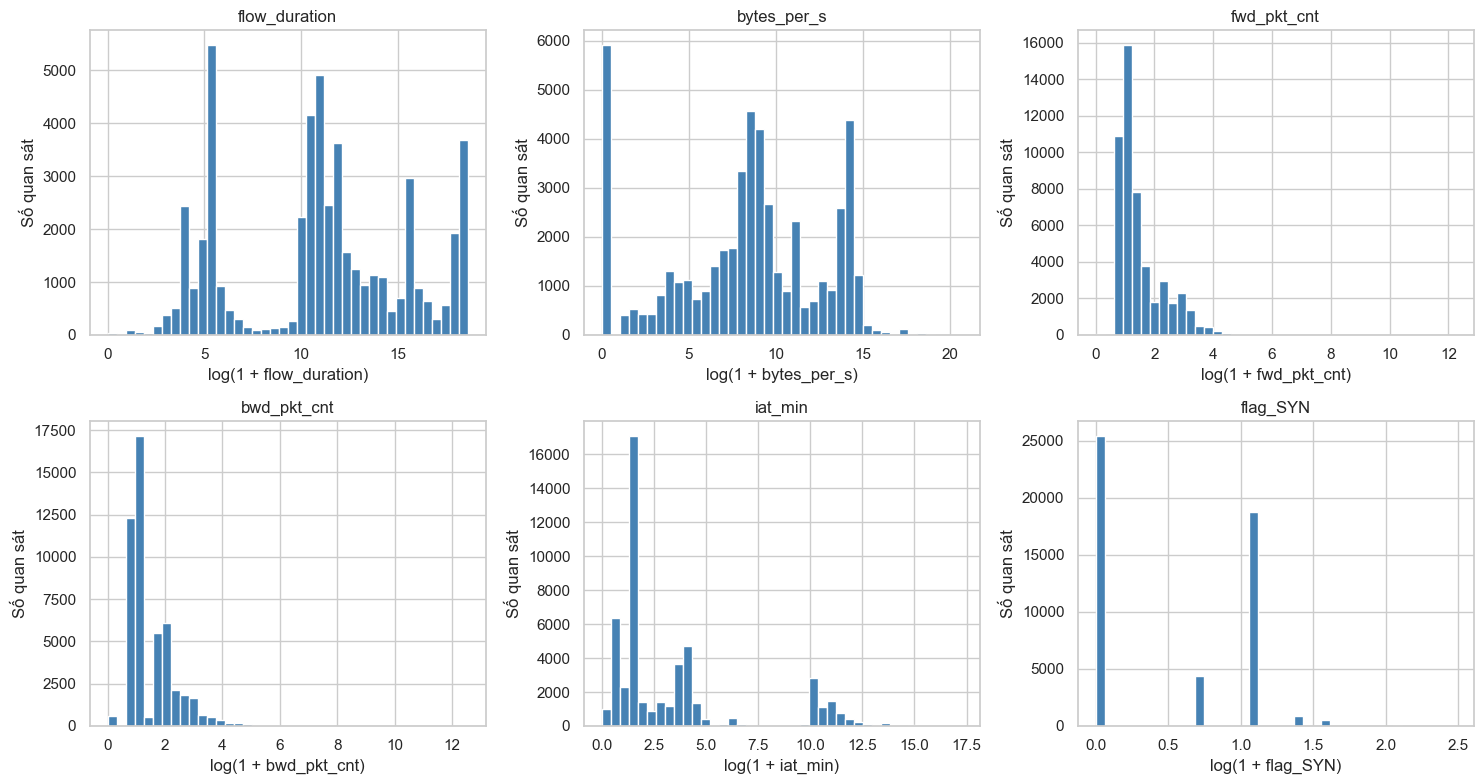

In [14]:
plot_df = df_raw.sample(n=min(50_000, len(df_raw)), random_state=RANDOM_STATE).copy()
plot_df['is_attack'] = target_eda.loc[plot_df.index].map({0: 'safe', 1: 'attack'})
plot_cols = ['flow_duration', 'bytes_per_s', 'fwd_pkt_cnt', 'bwd_pkt_cnt', 'iat_min', 'flag_SYN']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, plot_cols):
    values = plot_df[col].replace([np.inf, -np.inf], np.nan).dropna()
    # log1p dùng để quan sát các biến lệch phải; giữ riêng giá trị âm bất hợp lệ ở bảng vấn đề
    ax.hist(np.log1p(values[values >= 0]), bins=40, color='steelblue')
    ax.set(title=col, xlabel=f'log(1 + {col})', ylabel='Số quan sát')
plt.tight_layout()
plt.show()


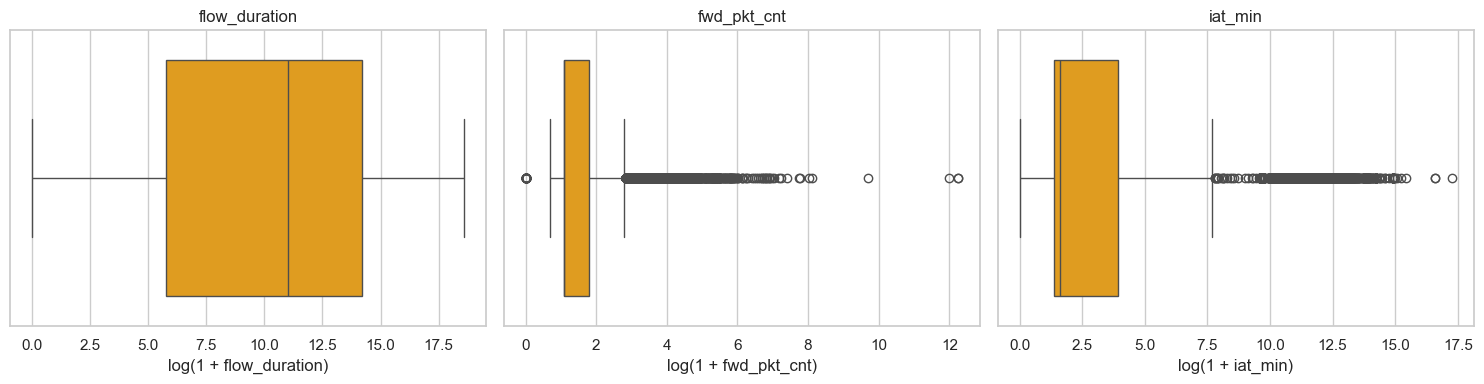

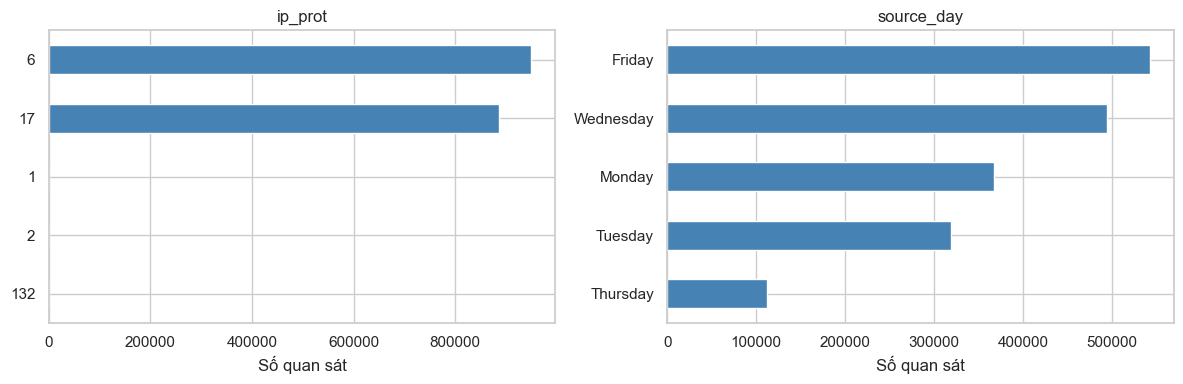

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['flow_duration', 'fwd_pkt_cnt', 'iat_min']):
    values = plot_df[col].replace([np.inf, -np.inf], np.nan).dropna()
    sns.boxplot(x=np.log1p(values[values >= 0]), ax=ax, color='orange')
    ax.set(title=col, xlabel=f'log(1 + {col})')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['ip_prot', 'source_day']):
    df_raw[col].value_counts().head(10).sort_values().plot.barh(ax=ax, color='steelblue')
    ax.set(title=col, xlabel='Số quan sát', ylabel='')
plt.tight_layout()
plt.show()


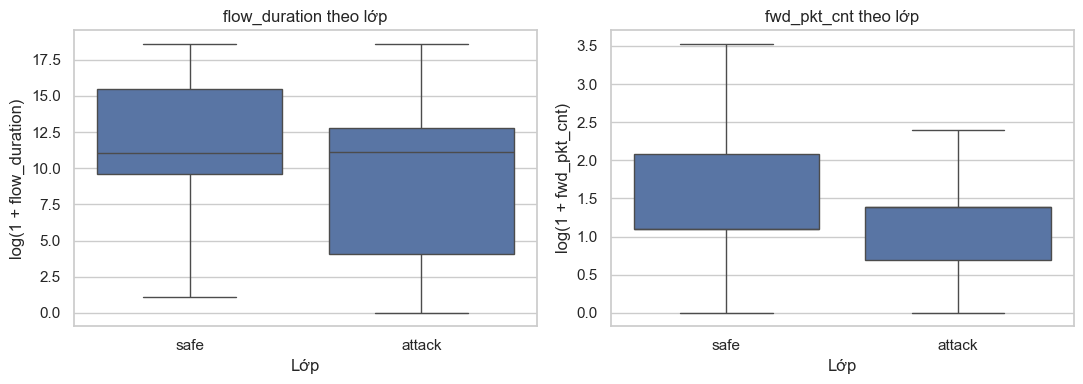

label,safe,attack
ip_prot,,
1,1.000,0.000
2,1.000,0.000
6,0.535,0.465
17,1.000,0.000
132,1.000,0.000


In [16]:
# Một số thuộc tính so với mục tiêu nhị phân
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['flow_duration', 'fwd_pkt_cnt']):
    view = plot_df.loc[plot_df['is_attack'].notna(), ['is_attack', col]].copy()
    view[col] = np.log1p(view[col].clip(lower=0))
    sns.boxplot(data=view, x='is_attack', y=col, ax=ax, showfliers=False)
    ax.set(xlabel='Lớp', ylabel=f'log(1 + {col})', title=f'{col} theo lớp')
plt.tight_layout()
plt.show()

protocol_rate = pd.crosstab(df_raw['ip_prot'], target_eda, normalize='index')
protocol_rate = protocol_rate.rename(columns={0: 'safe', 1: 'attack'})
display(protocol_rate.round(3))


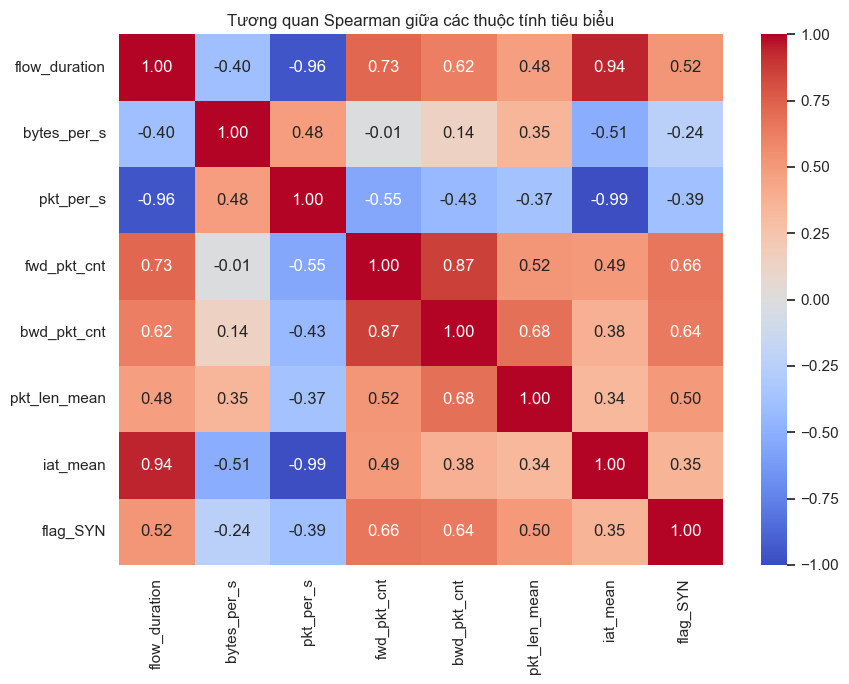

In [17]:
# Heatmap có chọn lọc, tránh ma trận 80+ cột khó đọc
corr_cols = ['flow_duration', 'bytes_per_s', 'pkt_per_s', 'fwd_pkt_cnt',
             'bwd_pkt_cnt', 'pkt_len_mean', 'iat_mean', 'flag_SYN']
corr = df_raw[corr_cols].corr(method='spearman')
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Tương quan Spearman giữa các thuộc tính tiêu biểu')
plt.tight_layout()
plt.show()


In [18]:
# Tổng hợp EDA tự động theo dữ liệu thực tế; đây là phát hiện để quyết định bước xử lý
findings = []
if int(df_raw.isna().sum().sum()):
    findings.append(['Có NaN', f"{int(df_raw.isna().sum().sum()):,} giá trị", 'Điền trên train, áp dụng sang test'])
if duplicate_count:
    findings.append(['Trùng toàn dòng', f'{duplicate_count:,} dòng', 'Xác minh rồi loại'])
if inf_count:
    findings.append(['Có vô cực', f'{inf_count:,} giá trị', 'Đánh dấu thiếu'])
if int(issue_table.loc[issue_table['Vấn đề'] == 'Giá trị âm', 'Số giá trị'].sum()):
    findings.append(['Giá trị âm bất hợp lý', 'Bảng kiểm tra miền giá trị', 'Đánh dấu thiếu'])
if len(valid_counts) > 1 and valid_counts.max() / valid_counts.min() > 2:
    findings.append(['Lớp mất cân bằng', f'Tỷ lệ {valid_counts.max() / valid_counts.min():.2f}:1', 'Dùng chỉ số đánh giá theo lớp'])
findings.append(['Mốc thời gian và ngày nguồn', 'timestamp/source_day gắn với đợt thu thập', 'Không dùng làm predictor mặc định'])
display(pd.DataFrame(findings, columns=['Phát hiện', 'Bằng chứng', 'Hướng xử lý']))


,Phát hiện,Bằng chứng,Hướng xử lý
0,Giá trị âm bất hợp lý,Bảng kiểm tra miền giá trị,Đánh dấu thiếu
1,Lớp mất cân bằng,Tỷ lệ 3.16:1,Dùng chỉ số đánh giá theo lớp
2,Mốc thời gian và ngày nguồn,timestamp/source_day gắn với đợt thu thập,Không dùng làm predictor mặc định


## 05. Tiền xử lý — làm sạch và nhật ký

Bỏ dòng chỉ khi thiếu nhãn, nhãn không hợp lệ hoặc trùng hoàn toàn. Giá trị đo âm và vô cực được chuyển thành thiếu để điền từ **train** sau khi chia dữ liệu. Không xóa outlier chỉ theo IQR. Mã `-1` của TCP window được giữ nguyên như một trạng thái riêng.

In [19]:
stats_before = {
    'Số dòng dữ liệu': len(df_raw),
    'Số thuộc tính đầu vào': df_raw.shape[1] - 1,
    'Số giá trị thiếu': int(df_raw.isna().sum().sum()),
    'Số dòng trùng toàn bộ': duplicate_count
}
clean_log = []

# Tiếp tục trên cùng DataFrame để tránh giữ hai bản 900 MB trong RAM
df_clean = df_raw
del df_raw, plot_df

bad_label = ~df_clean['label'].astype('string').str.strip().str.lower().isin(
    ['benign', 'bot', 'ddos', 'dos_goldeneye', 'dos_hulk', 'dos_slowhttptest',
     'dos_slowloris', 'ftp_patator', 'heartbleed', 'portscan', 'ssh_patator',
     'webattack_bruteforce', 'webattack_sql_injection', 'webattack_xss']
)
n_bad_label = int(bad_label.sum())
if n_bad_label:
    df_clean = df_clean.loc[~bad_label].copy()
clean_log.append(['Nhãn thiếu/không hợp lệ', n_bad_label, 0, 0, 'Không thể huấn luyện có giám sát'])

duplicate_mask = df_clean.duplicated()
n_duplicate = int(duplicate_mask.sum())
if n_duplicate:
    df_clean = df_clean.loc[~duplicate_mask].copy()
clean_log.append(['Trùng toàn bộ', n_duplicate, 0, 0, 'Bản ghi lặp hoàn toàn'])

df_clean['is_attack'] = df_clean['label'].astype('string').str.strip().str.lower().ne('benign').astype('int8')
print('Dữ liệu sau loại dòng:', df_clean.shape)


Dữ liệu sau loại dòng: (1837498, 85)


In [20]:
# Giữ logic kiểm tra miền giá trị từ notebook cũ; dùng NaN để tiện điền khuyết sau chia tập
n_inf = 0
for col in numeric_cols:
    bad = np.isinf(df_clean[col])
    n_inf += int(bad.sum())
    if bad.any():
        df_clean.loc[bad, col] = np.nan
clean_log.append(['Vô cực → NaN', 0, 0, n_inf, 'Không phải giá trị hữu hạn'])

n_invalid = 0
for col in ['src_port', 'dst_port', 'ip_prot']:
    upper = 255 if col == 'ip_prot' else 65535
    bad = df_clean[col].notna() & (~df_clean[col].between(0, upper) | df_clean[col].mod(1).ne(0))
    n_invalid += int(bad.sum())
    if bad.any():
        df_clean.loc[bad, col] = np.nan

for col in nonnegative_cols:
    bad = df_clean[col].lt(0)
    n_invalid += int(bad.sum())
    if bad.any():
        df_clean.loc[bad, col] = np.nan
clean_log.append(['Ngoài miền → NaN', 0, 0, n_invalid, 'Cổng/giao thức sai miền hoặc đại lượng âm'])

clean_table = pd.DataFrame(clean_log, columns=['Bước', 'Số dòng loại', 'Số cột loại', 'Số giá trị xử lý', 'Lý do'])
display(clean_table)


,Bước,Số dòng loại,Số cột loại,Số giá trị xử lý,Lý do
0,Nhãn thiếu/không hợp lệ,0,0,0,Không thể huấn luyện có giám sát
1,Trùng toàn bộ,0,0,0,Bản ghi lặp hoàn toàn
2,Vô cực → NaN,0,0,0,Không phải giá trị hữu hạn
3,Ngoài miền → NaN,0,0,2270,Cổng/giao thức sai miền hoặc đại lượng âm


## 06. Chia train/test và phân hạng thuộc tính

Bỏ trước các cột định danh, nhãn gốc, thời điểm và ngày nguồn vì chúng có thể làm mô hình nhớ địa chỉ hoặc lịch thu thập. Kiểm tra biến hằng và tỷ lệ thiếu trên train. MI là tín hiệu tham khảo, không phải ngưỡng loại tự động. Dùng mẫu có phân tầng từ train để việc tính MI và so sánh mô hình khả thi với 1,8 triệu dòng.

In [21]:
target_col = 'is_attack'
train_idx, test_idx = train_test_split(
    df_clean.index, test_size=0.2, random_state=RANDOM_STATE,
    stratify=df_clean[target_col]
)
print('Train:', len(train_idx), 'Test:', len(test_idx))

id_cols = ['flow_id', 'src_addr', 'dst_addr', 'timestamp', 'source_day', 'label']
feature_cols = [c for c in df_clean.columns if c not in id_cols + [target_col]]
missing_rate = df_clean.loc[train_idx, feature_cols].isna().mean()
drop_missing = missing_rate[missing_rate >= 0.5].index.tolist()
drop_constant = [c for c in feature_cols if df_clean.loc[train_idx, c].nunique(dropna=True) <= 1]
drop_cols = set(drop_missing + drop_constant)
candidate_cols = [c for c in feature_cols if c not in drop_cols]

print('Loại theo vai trò:', id_cols)
print('Thiếu >= 50%:', drop_missing)
print('Biến hằng:', drop_constant)
print('Ứng viên còn lại:', len(candidate_cols))

# Tách validation ngay từ train để MI không nhìn thấy nhãn validation
if len(train_idx) > 100_000:
    model_idx, _ = train_test_split(
        train_idx, train_size=100_000,
        stratify=df_clean.loc[train_idx, target_col], random_state=RANDOM_STATE + 1
    )
else:
    model_idx = train_idx
fit_idx, val_idx = train_test_split(
    model_idx, test_size=0.2, stratify=df_clean.loc[model_idx, target_col],
    random_state=RANDOM_STATE
)


Train: 1469998 Test: 367500
Loại theo vai trò: ['flow_id', 'src_addr', 'dst_addr', 'timestamp', 'source_day', 'label']
Thiếu >= 50%: []
Biến hằng: ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']
Ứng viên còn lại: 75


,Thuộc tính,Missing % (train),MI Score
0,bwd_pkt_len_mean,0.0,0.468260
1,bwd_subflow_bytes_mean,0.0,0.466484
2,bwd_pkt_len_tot,0.0,0.462815
3,pkt_len_mean,0.0,0.456334
4,pkt_len_max,0.0,0.450253
...,...,...,...
70,fwd_bulk_pkt_mean,0.0,0.007355
71,fwd_bulk_bytes_mean,0.0,0.006247
72,flag_cwr,0.0,0.004310
73,bwd_pkt_len_min,0.0,0.001468


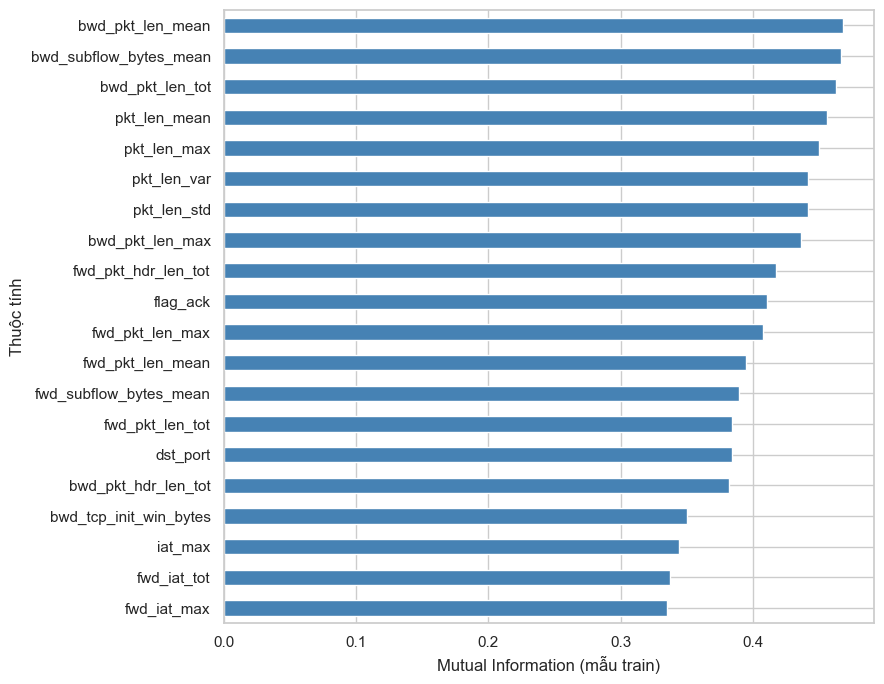

In [22]:
# Phân hạng MI trên mẫu train, điền tạm thời bằng median của chính mẫu train
if len(fit_idx) > 30_000:
    mi_idx, _ = train_test_split(
        fit_idx, train_size=30_000,
        stratify=df_clean.loc[fit_idx, target_col], random_state=RANDOM_STATE
    )
else:
    mi_idx = fit_idx
X_mi = df_clean.loc[mi_idx, candidate_cols].copy()
y_mi = df_clean.loc[mi_idx, target_col]
for col in candidate_cols:
    X_mi[col] = pd.to_numeric(X_mi[col], errors='coerce')
    median = X_mi[col].median()
    X_mi[col] = X_mi[col].fillna(median if pd.notna(median) else 0)

mi_scores = mutual_info_classif(
    X_mi, y_mi, discrete_features=[c == 'ip_prot' for c in candidate_cols],
    random_state=RANDOM_STATE
)
ranking = pd.DataFrame({
    'Thuộc tính': candidate_cols,
    'Missing % (train)': (missing_rate[candidate_cols].to_numpy() * 100).round(3),
    'MI Score': mi_scores
}).sort_values('MI Score', ascending=False).reset_index(drop=True)
display(ranking)

ranking.head(20).sort_values('MI Score').plot.barh(
    x='Thuộc tính', y='MI Score', figsize=(9, 7), legend=False, color='steelblue'
)
plt.xlabel('Mutual Information (mẫu train)')
plt.ylabel('Thuộc tính')
plt.tight_layout()
plt.show()
del X_mi, y_mi


## 07. Lựa chọn thuộc tính bằng validation

So sánh tất cả ứng viên với bộ gọn gồm 12 và 20 cột, có bổ sung các thuộc tính mạng thiết yếu nếu MI không đưa lên đầu. Các mô hình ở đây chỉ dùng để **kiểm tra lựa chọn thuộc tính**, chưa phải kết quả Classification cuối cùng. Chọn bộ ít cột nhất có Average Precision không thấp hơn kết quả tốt nhất quá 0,01. Test được giữ riêng đến bước sau.

In [23]:
# Các cột quan trọng về mặt nghiệp vụ; chỉ thêm khi còn hợp lệ
domain_cols = ['flow_duration', 'fwd_pkt_cnt', 'bwd_pkt_cnt', 'bytes_per_s',
               'dst_port', 'ip_prot', 'flag_SYN']
domain_cols = [c for c in domain_cols if c in candidate_cols]

def top_features(n):
    features = domain_cols.copy()
    for col in ranking['Thuộc tính']:
        if col not in features:
            features.append(col)
        if len(features) >= n:
            break
    return features

feature_sets = {
    'Top 12 + nghiệp vụ': top_features(min(12, len(candidate_cols))),
    'Top 20 + nghiệp vụ': top_features(min(20, len(candidate_cols))),
    'Tất cả hợp lệ': candidate_cols
}

validation_rows = []
for name, cols in feature_sets.items():
    X_fit = df_clean.loc[fit_idx, cols].copy()
    X_val = df_clean.loc[val_idx, cols].copy()
    medians = X_fit.median(numeric_only=True).fillna(0)
    X_fit = X_fit.fillna(medians)
    X_val = X_val.fillna(medians)

    model = HistGradientBoostingClassifier(
        max_iter=60, max_leaf_nodes=15, random_state=RANDOM_STATE
    )
    model.fit(X_fit, df_clean.loc[fit_idx, target_col])
    score = model.predict_proba(X_val)[:, 1]
    pred = (score >= 0.5).astype('int8')
    y_val = df_clean.loc[val_idx, target_col]
    validation_rows.append([
        name, len(cols), average_precision_score(y_val, score),
        balanced_accuracy_score(y_val, pred), f1_score(y_val, pred),
        recall_score(y_val, pred)
    ])
    del X_fit, X_val, model

validation_table = pd.DataFrame(
    validation_rows,
    columns=['Bộ thuộc tính', 'Số cột', 'Average Precision', 'Balanced Accuracy', 'F1', 'Recall']
).sort_values('Số cột')
display(validation_table.round(4))


,Bộ thuộc tính,Số cột,Average Precision,Balanced Accuracy,F1,Recall
0,Top 12 + nghiệp vụ,12,0.9997,0.9974,0.9963,0.9958
1,Top 20 + nghiệp vụ,20,0.9999,0.9973,0.9962,0.9956
2,Tất cả hợp lệ,75,1.0000,0.9992,0.9984,0.9990


In [24]:
best_ap = validation_table['Average Precision'].max()
eligible = validation_table[validation_table['Average Precision'] >= best_ap - 0.01]
selected_name = eligible.sort_values('Số cột').iloc[0]['Bộ thuộc tính']
selected_features = feature_sets[selected_name]

ranking['Quyết định'] = ranking['Thuộc tính'].map(
    lambda c: 'Giữ' if c in selected_features else 'Chưa chọn'
)
ranking['Lý do'] = ranking['Thuộc tính'].map(
    lambda c: 'Có vai trò nghiệp vụ và qua kiểm tra validation' if c in domain_cols and c in selected_features
    else ('Bộ thuộc tính được chọn đạt tiêu chí validation' if c in selected_features
          else 'Chưa cần cho bộ gọn; xem lại khi khai phá luật')
)

excluded = pd.DataFrame({
    'Thuộc tính': id_cols + sorted(drop_cols),
    'Missing % (train)': [round(missing_rate.get(c, np.nan) * 100, 3) for c in id_cols + sorted(drop_cols)],
    'MI Score': np.nan,
    'Quyết định': 'Loại',
    'Lý do': [('Định danh/nhãn gốc/ngày thu thập' if c in id_cols else
              'Biến hằng' if c in drop_constant else 'Thiếu >= 50% trên train')
             for c in id_cols + sorted(drop_cols)]
})
selection_table = pd.concat([ranking, excluded], ignore_index=True)
print('Bộ được chọn:', selected_name, '—', len(selected_features), 'thuộc tính')
display(selection_table)


Bộ được chọn: Top 12 + nghiệp vụ — 12 thuộc tính


,Thuộc tính,Missing % (train),MI Score,Quyết định,Lý do
0,bwd_pkt_len_mean,0.0,0.468260,Giữ,Bộ thuộc tính được chọn đạt tiêu chí validation
1,bwd_subflow_bytes_mean,0.0,0.466484,Giữ,Bộ thuộc tính được chọn đạt tiêu chí validation
2,bwd_pkt_len_tot,0.0,0.462815,Giữ,Bộ thuộc tính được chọn đạt tiêu chí validation
3,pkt_len_mean,0.0,0.456334,Giữ,Bộ thuộc tính được chọn đạt tiêu chí validation
4,pkt_len_max,0.0,0.450253,Giữ,Bộ thuộc tính được chọn đạt tiêu chí validation
...,...,...,...,...,...
79,source_day,NaN,NaN,Loại,Định danh/nhãn gốc/ngày thu thập
80,label,NaN,NaN,Loại,Định danh/nhãn gốc/ngày thu thập
81,bwd_flag_urg,0.0,NaN,Loại,Biến hằng
82,flag_urg,0.0,NaN,Loại,Biến hằng


## 08. Hai dạng dữ liệu cho phân lớp và khai phá luật

Hai nhánh dùng cùng dòng và cùng danh sách thuộc tính nền. Median được học từ train rồi dùng cho test. Phân lớp giữ biến số; `ip_prot` vẫn là mã giao thức để mô hình cây xử lý. Nhánh luật rời rạc hóa từ **ngưỡng quantile của train**; vì số hạng mục của cổng có thể rất lớn, cổng cũng được chia khoảng. Chưa khai phá luật hay tạo Rule_1/2/3 ở notebook này.

In [25]:
X_train = df_clean.loc[train_idx, selected_features].copy()
X_test = df_clean.loc[test_idx, selected_features].copy()
y_train = df_clean.loc[train_idx, target_col].copy()
y_test = df_clean.loc[test_idx, target_col].copy()

median_train = X_train.median(numeric_only=True).fillna(0)
missing_train_before = int(X_train.isna().sum().sum())
missing_test_before = int(X_test.isna().sum().sum())
X_train = X_train.fillna(median_train)
X_test = X_test.fillna(median_train)

print('Đã điền trên train:', missing_train_before, 'giá trị')
print('Đã điền trên test:', missing_test_before, 'giá trị')
print('X_train:', X_train.shape, 'X_test:', X_test.shape)
display(X_train.head())


Đã điền trên train: 0 giá trị
Đã điền trên test: 0 giá trị
X_train: (1469998, 12) X_test: (367500, 12)


,flow_duration,fwd_pkt_cnt,bwd_pkt_cnt,bytes_per_s,dst_port,ip_prot,flag_SYN,bwd_pkt_len_mean,bwd_subflow_bytes_mean,bwd_pkt_len_tot,pkt_len_mean,pkt_len_max
477472,162,2,2,1.283951e+06,53,17,0,66.0,132.0,132,52.0,66.0
1773055,186,2,2,1.032258e+06,53,17,0,56.0,112.0,112,48.0,56.0
269468,46,1,1,0.000000e+00,2909,6,1,0.0,0.0,0,0.0,0.0
268764,75,1,1,0.000000e+00,5963,6,1,0.0,0.0,0,0.0,0.0
837689,31486,2,2,1.029029e+04,53,17,0,127.0,254.0,254,81.0,127.0


In [26]:
# Lưu ranh giới từ train; pd.Categorical giúp bảng item tiết kiệm bộ nhớ
arm_edges = {}
for col in selected_features:
    if col == 'ip_prot':
        continue
    edges = np.unique(np.quantile(X_train[col], [0, .25, .5, .75, 1]))
    if len(edges) > 1:
        edges[0], edges[-1] = -np.inf, np.inf
    arm_edges[col] = edges

def to_items(X):
    item_df = pd.DataFrame(index=X.index)
    for col in selected_features:
        if col == 'ip_prot':
            item_df[col] = pd.Categorical('ip_prot=' + X[col].astype('Int64').astype(str))
        elif len(arm_edges[col]) == 1:
            item_df[col] = pd.Categorical([f'{col}=all'] * len(X))
        else:
            labels = [f'{col}=Q{i+1}' for i in range(len(arm_edges[col]) - 1)]
            item_df[col] = pd.cut(X[col], bins=arm_edges[col], labels=labels, include_lowest=True)
    return item_df

arm_train = to_items(X_train)
arm_test = to_items(X_test)
print('ARM train:', arm_train.shape, 'ARM test:', arm_test.shape)
display(arm_train.head())


ARM train: (1469998, 12) ARM test: (367500, 12)


,flow_duration,fwd_pkt_cnt,bwd_pkt_cnt,bytes_per_s,dst_port,ip_prot,flag_SYN,bwd_pkt_len_mean,bwd_subflow_bytes_mean,bwd_pkt_len_tot,pkt_len_mean,pkt_len_max
477472,flow_duration=Q1,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q2,bytes_per_s=Q4,dst_port=Q1,ip_prot=17,flag_SYN=Q1,bwd_pkt_len_mean=Q2,bwd_subflow_bytes_mean=Q2,bwd_pkt_len_tot=Q2,pkt_len_mean=Q1,pkt_len_max=Q1
1773055,flow_duration=Q1,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q2,bytes_per_s=Q4,dst_port=Q1,ip_prot=17,flag_SYN=Q1,bwd_pkt_len_mean=Q1,bwd_subflow_bytes_mean=Q2,bwd_pkt_len_tot=Q2,pkt_len_mean=Q1,pkt_len_max=Q1
269468,flow_duration=Q1,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q1,bytes_per_s=Q1,dst_port=Q4,ip_prot=6,flag_SYN=Q1,bwd_pkt_len_mean=Q1,bwd_subflow_bytes_mean=Q1,bwd_pkt_len_tot=Q1,pkt_len_mean=Q1,pkt_len_max=Q1
268764,flow_duration=Q1,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q1,bytes_per_s=Q1,dst_port=Q4,ip_prot=6,flag_SYN=Q1,bwd_pkt_len_mean=Q1,bwd_subflow_bytes_mean=Q1,bwd_pkt_len_tot=Q1,pkt_len_mean=Q1,pkt_len_max=Q1
837689,flow_duration=Q2,fwd_pkt_cnt=Q1,bwd_pkt_cnt=Q2,bytes_per_s=Q3,dst_port=Q1,ip_prot=17,flag_SYN=Q1,bwd_pkt_len_mean=Q3,bwd_subflow_bytes_mean=Q3,bwd_pkt_len_tot=Q3,pkt_len_mean=Q2,pkt_len_max=Q2


## 09. Thống kê trước/sau và đầu ra

`Số dòng trùng toàn bộ` sau xử lý được kiểm tra trên các cột gốc còn lại. Nếu chỉ nhìn bộ thuộc tính đã chọn, nhiều luồng khác nhau có thể trùng biểu diễn; đó không phải bản ghi gốc bị lặp và không nên xóa tiếp.

In [27]:
stats_after = {
    'Số dòng dữ liệu': len(df_clean),
    'Số thuộc tính đầu vào': len(selected_features),
    'Số giá trị thiếu': int(X_train.isna().sum().sum() + X_test.isna().sum().sum()),
    'Số dòng trùng toàn bộ': int(df_clean.drop(columns=target_col).duplicated().sum())
}
comparison = pd.DataFrame({'Trước xử lý': stats_before, 'Sau xử lý': stats_after})
comparison['Chênh lệch'] = comparison['Sau xử lý'] - comparison['Trước xử lý']
comparison.loc['Số thuộc tính bị loại', 'Trước xử lý'] = 0
comparison.loc['Số thuộc tính bị loại', 'Sau xử lý'] = stats_before['Số thuộc tính đầu vào'] - len(selected_features)
comparison.loc['Số thuộc tính bị loại', 'Chênh lệch'] = comparison.loc['Số thuộc tính bị loại', 'Sau xử lý']
display(comparison.astype('int64'))

clean_log.append(['Loại thuộc tính', 0, stats_before['Số thuộc tính đầu vào'] - len(selected_features), 0,
                  'Vai trò, biến hằng/thiếu và so sánh validation'])
clean_log.append(['Điền khuyết từ train', 0, 0, missing_train_before + missing_test_before,
                  'Median của train, áp dụng cho cả train/test'])
display(pd.DataFrame(clean_log, columns=['Bước', 'Số dòng loại', 'Số cột loại', 'Số giá trị xử lý', 'Lý do']))

assert X_train.columns.tolist() == X_test.columns.tolist() == arm_train.columns.tolist() == arm_test.columns.tolist()
assert len(X_train) + len(X_test) == len(df_clean)
assert X_train.isna().sum().sum() + X_test.isna().sum().sum() == 0
assert arm_train.isna().sum().sum() + arm_test.isna().sum().sum() == 0
print('Đã kiểm tra cùng dòng/cột và không còn giá trị thiếu ở hai nhánh.')


,Trước xử lý,Sau xử lý,Chênh lệch
Số dòng dữ liệu,1837498,1837498,0
Số thuộc tính đầu vào,83,12,-71
Số giá trị thiếu,0,0,0
Số dòng trùng toàn bộ,0,0,0
Số thuộc tính bị loại,0,71,71


,Bước,Số dòng loại,Số cột loại,Số giá trị xử lý,Lý do
0,Nhãn thiếu/không hợp lệ,0,0,0,Không thể huấn luyện có giám sát
1,Trùng toàn bộ,0,0,0,Bản ghi lặp hoàn toàn
2,Vô cực → NaN,0,0,0,Không phải giá trị hữu hạn
3,Ngoài miền → NaN,0,0,2270,Cổng/giao thức sai miền hoặc đại lượng âm
4,Loại thuộc tính,0,71,0,"Vai trò, biến hằng/thiếu và so sánh validation"
5,Điền khuyết từ train,0,0,0,"Median của train, áp dụng cho cả train/test"


Đã kiểm tra cùng dòng/cột và không còn giá trị thiếu ở hai nhánh.


### Ghi chú cho các bước tiếp theo

- Dùng `X_train`, `X_test`, `y_train`, `y_test` khi huấn luyện Classification. Mã `ip_prot` nên được one-hot nếu dùng mô hình tuyến tính.
- Dùng `arm_train`, `arm_test` để tạo giao dịch cho CHARM và FP-Growth. Nếu khai phá luật có chứa nhãn, chỉ học luật trên train; sau đó đánh giá độ phủ và tạo đúng ba cột `Rule_1`–`Rule_3` cho cả train/test từ **vế trái của luật**.
- Có thể đổi bộ thuộc tính được chọn sau khi phân tích luật, nhưng cần chạy lại so sánh validation và ghi rõ lý do trong báo cáo. Chưa dùng tập test để quyết định thuộc tính.
